# Deep Learning, Phase 3 (Sequential Models), Day 3: LSTM and GRU
Yesterday the plain RNN could not reliably remember the first element of a long sequence, because the gradient vanishes. Today:
1. LSTM and GRU in PyTorch: shapes and parameter counts  2. The **same memory test**, with several seeds  3. Forecasting: RNN vs LSTM vs GRU  4. Looking inside an LSTM: the gates over time


## The idea in short
- **LSTM:** besides the hidden state `h`, it has a **cell state `c`** (long-term memory). Three gates, each a number between 0 and 1 for every unit:
  - **forget gate `f`:** how much of the old cell state to keep
  - **input gate `i`:** how much of the new candidate `g` to write
  - **output gate `o`:** how much of the cell state to reveal as `h`
  - `c_t = f * c_(t-1) + i * g` and `h_t = o * tanh(c_t)`. The cell state is updated by **addition**, so the gradient can flow back over many steps when `f` is close to 1.
- **GRU:** two gates (update, reset), no separate cell state. Fewer parameters, often similar results.

In [1]:
import copy, time, numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import torch, torch.nn as nn
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
sns.set_theme(style='whitegrid')
np.random.seed(42); torch.manual_seed(0)

## 1. Shapes and parameter counts
`nn.LSTM` returns `output, (h_n, c_n)`. `nn.GRU` and `nn.RNN` return `output, h_n`. With the same hidden size, an LSTM has about **4x** the weights of an RNN (4 sets: three gates + candidate) and a GRU about **3x**.

In [2]:
x = torch.randn(4, 20, 1)
for name, cell in [('RNN', nn.RNN), ('GRU', nn.GRU), ('LSTM', nn.LSTM)]:
    m = cell(1, 32, batch_first=True); out, state = m(x)
    shapes = [tuple(s.shape) for s in state] if isinstance(state, tuple) else tuple(state.shape)
    print(f'{name:5s} output {tuple(out.shape)} | state {shapes} | parameters {sum(p.numel() for p in m.parameters())}')

RNN   output (4, 20, 32) | state (1, 4, 32) | parameters 1120
GRU   output (4, 20, 32) | state (1, 4, 32) | parameters 3360
LSTM  output (4, 20, 32) | state [(1, 4, 32), (1, 4, 32)] | parameters 4480


## 2. The memory test again: RNN vs GRU vs LSTM
Same task as Day 2: the label is whether the **first** number of a random sequence is positive. This time we run **3 different seeds** for each model, because one run can be lucky or unlucky (as you saw yesterday at length 100). Settings: Adam with a smaller learning rate (0.001), 60 epochs, gradient clipping. For the LSTM we also start the forget-gate bias at 1 (a standard trick: the forget gate begins mostly open). The GRU and RNN have no such setting, so keep that in mind when comparing.

In [3]:
def memory_data(n, T, seed):
    g = torch.Generator().manual_seed(seed); x = torch.randn(n, T, 1, generator=g); return x, (x[:, 0, 0] > 0).float()

class MemoryNet(nn.Module):
    def __init__(self, hidden=32, kind='rnn'):
        super().__init__(); self.rnn = {'rnn': nn.RNN, 'lstm': nn.LSTM, 'gru': nn.GRU}[kind](1, hidden, batch_first=True); self.fc = nn.Linear(hidden, 1)
        if kind == 'lstm':                                    # common LSTM trick: start with the forget gate mostly OPEN (bias 1), so memory is kept at the start
            with torch.no_grad(): self.rnn.bias_hh_l0[hidden:2 * hidden].fill_(1.0)
    def forward(self, x): o, _ = self.rnn(x); return self.fc(o[:, -1]).squeeze(1)

def run_memory_task(T, kind='rnn', epochs=60, seed=0, lr=0.001, return_model=False):
    torch.manual_seed(seed); xtr, ytr = memory_data(2000, T, 1); xva, yva = memory_data(500, T, 2)
    m = MemoryNet(kind=kind); opt = torch.optim.Adam(m.parameters(), lr=lr); lf = nn.BCEWithLogitsLoss(); accs = []
    for ep in range(epochs):
        m.train(); perm = torch.randperm(2000)
        for i in range(0, 2000, 64):
            idx = perm[i:i + 64]; opt.zero_grad(); lf(m(xtr[idx]), ytr[idx]).backward(); nn.utils.clip_grad_norm_(m.parameters(), 1.0); opt.step()
        m.eval()
        with torch.no_grad(): accs.append(((m(xva) > 0).float() == yva).float().mean().item())
    return (accs, m) if return_model else accs

lengths, kinds, seeds = [50, 100], ['rnn', 'gru', 'lstm'], [0, 1, 2]
res, times = {}, {}
for T in lengths:
    for k in kinds:
        t0 = time.time(); res[(T, k)] = [run_memory_task(T, k, seed=s) for s in seeds]; times[(T, k)] = (time.time() - t0) / len(seeds)
rows = []
for T in lengths:
    for k in kinds:
        finals = [c[-1] for c in res[(T, k)]]
        rows.append({'length': T, 'model': k.upper(), 'mean accuracy': np.mean(finals), 'min': np.min(finals), 'max': np.max(finals), 'sec per run': times[(T, k)]})
table = pd.DataFrame(rows); display(table.round(3))

,length,model,mean accuracy,min,max,sec per run
0,50,RNN,0.944,0.914,0.968,20.705
1,50,GRU,0.512,0.498,0.528,36.332
2,50,LSTM,0.978,0.964,0.986,20.223
3,100,RNN,0.791,0.510,0.934,23.875
4,100,GRU,0.494,0.476,0.506,64.794
5,100,LSTM,0.951,0.920,0.988,36.611


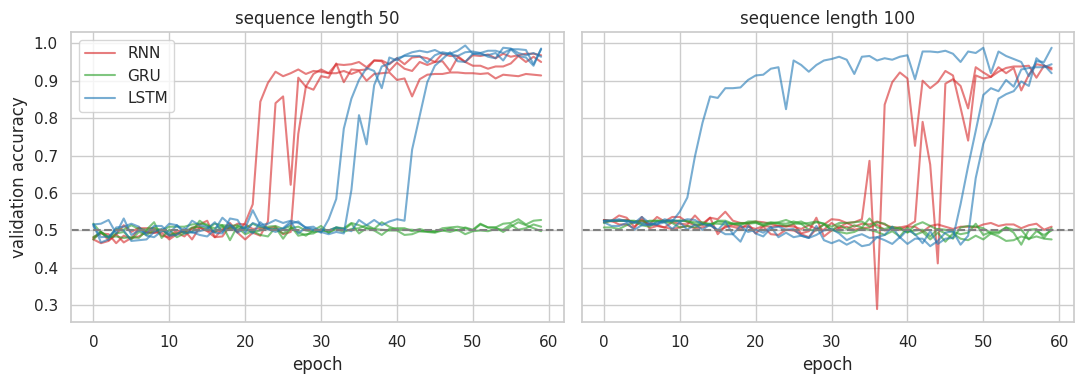

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for a, T in zip(ax, lengths):
    for k, col in zip(kinds, ['tab:red', 'tab:green', 'tab:blue']):
        for j, c in enumerate(res[(T, k)]): a.plot(c, color=col, alpha=.6, label=k.upper() if j == 0 else None)
    a.axhline(0.5, color='grey', ls='--'); a.set(title=f'sequence length {T}', xlabel='epoch');
ax[0].set_ylabel('validation accuracy'); ax[0].legend(); plt.tight_layout(); plt.show()



## 3. Forecasting: RNN vs GRU vs LSTM
The same noisy sine data and split as Days 1 and 2.

In [5]:
n = 1200; t = np.arange(n)
series = np.sin(0.05 * t) + 0.3 * np.sin(0.013 * t) + 0.1 * np.random.randn(n)
n_tr, n_va = int(0.70 * n), int(0.15 * n)
s_train, s_val, s_test = series[:n_tr], series[n_tr:n_tr + n_va], series[n_tr + n_va:]
scaler = StandardScaler().fit(s_train.reshape(-1, 1))
tr, va, te = (scaler.transform(s.reshape(-1, 1)).ravel() for s in (s_train, s_val, s_test))
def make_windows(x, k): return np.array([x[i:i + k] for i in range(len(x) - k)]), x[k:]
K = 20
Xtr, ytr = make_windows(tr, K); Xva, yva = make_windows(va, K); Xte, yte = make_windows(te, K)   # test stays locked
def scores(y_true, y_pred): return {'MAE': mean_absolute_error(y_true, y_pred), 'RMSE': np.sqrt(mean_squared_error(y_true, y_pred))}
base = pd.DataFrame({'Naive (last value)': scores(yva, Xva[:, -1]), 'Linear regression': scores(yva, LinearRegression().fit(Xtr, ytr).predict(Xva))}).T

class Forecaster(nn.Module):
    def __init__(self, kind='rnn', hidden=32, layers=1):
        super().__init__(); self.rnn = {'rnn': nn.RNN, 'lstm': nn.LSTM, 'gru': nn.GRU}[kind](1, hidden, num_layers=layers, batch_first=True); self.fc = nn.Linear(hidden, 1)
    def forward(self, x): o, _ = self.rnn(x); return self.fc(o[:, -1]).squeeze(1)

to_t = lambda a: torch.tensor(a, dtype=torch.float32)
Xtr_t, ytr_t, Xva_t, yva_t = to_t(Xtr)[..., None], to_t(ytr), to_t(Xva)[..., None], to_t(yva)

def train(model, epochs=40, lr=5e-3, batch=64, clip=1.0, seed=0):
    torch.manual_seed(seed); opt = torch.optim.Adam(model.parameters(), lr=lr); lf = nn.MSELoss(); best, best_state, hist = float('inf'), None, []
    for ep in range(epochs):
        model.train(); perm = torch.randperm(len(Xtr_t))
        for i in range(0, len(perm), batch):
            idx = perm[i:i + batch]; opt.zero_grad(); lf(model(Xtr_t[idx]), ytr_t[idx]).backward(); nn.utils.clip_grad_norm_(model.parameters(), clip); opt.step()
        model.eval()
        with torch.no_grad(): vl = lf(model(Xva_t), yva_t).item()
        hist.append(vl)
        if vl < best: best, best_state = vl, copy.deepcopy(model.state_dict())
    model.load_state_dict(best_state); return hist

rows, preds, hists = {}, {}, {}
for k in kinds:
    maes = []
    for s in seeds:
        m = Forecaster(k); t0 = time.time(); h = train(m, seed=s); sec = time.time() - t0; m.eval()
        with torch.no_grad(): p = m(Xva_t).numpy()
        maes.append(mean_absolute_error(yva, p))
        if s == 0: preds[k], hists[k] = p, h; rows[k.upper()] = {'parameters': sum(q.numel() for q in m.parameters()), 'sec per run': sec}
    rows[k.upper()].update({'val MAE (mean of 3 seeds)': np.mean(maes), 'min': np.min(maes), 'max': np.max(maes)})
display(base.round(4)); display(pd.DataFrame(rows).T.round(4))

,MAE,RMSE
Naive (last value),0.1548,0.1894
Linear regression,0.1156,0.1440


,parameters,sec per run,val MAE (mean of 3 seeds),min,max
RNN,1153.0,1.6906,0.1231,0.1217,0.1245
GRU,3393.0,4.8260,0.1150,0.1138,0.1162
LSTM,4513.0,2.9726,0.1142,0.1132,0.1155


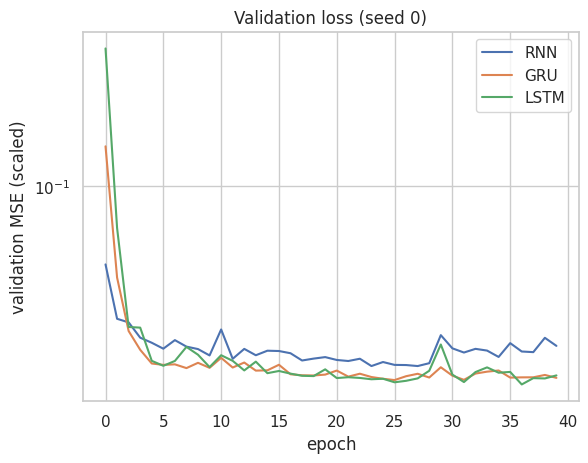

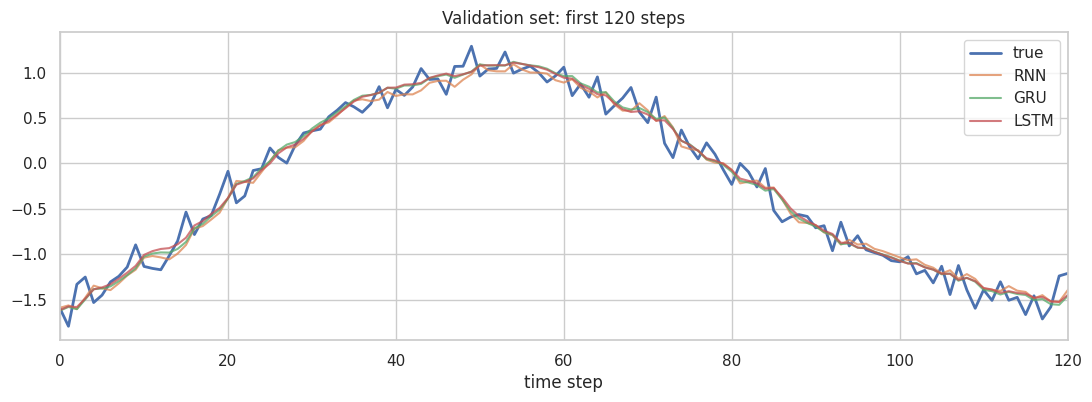

In [6]:
for k in kinds: plt.plot(hists[k], label=k.upper())
plt.yscale('log'); plt.xlabel('epoch'); plt.ylabel('validation MSE (scaled)'); plt.legend(); plt.title('Validation loss (seed 0)'); plt.show()
plt.figure(figsize=(13, 4)); plt.plot(yva, lw=2, label='true')
for k in kinds: plt.plot(preds[k], alpha=.75, label=k.upper())
plt.xlim(0, 120); plt.legend(); plt.xlabel('time step'); plt.title('Validation set: first 120 steps'); plt.show()

## 4. Looking inside an LSTM: the gates over time
We train an LSTM on the memory task (length 20) and compute its gates by hand from the weights. PyTorch stores them stacked in the order **input, forget, cell-candidate, output**.

In [7]:
T = 20; _, net = run_memory_task(T, 'lstm', seed=0, return_model=True)
xva, yva_m = memory_data(500, T, 2); net.eval()
with torch.no_grad(): print('Validation accuracy of this LSTM (length 20):', ((net(xva) > 0).float() == yva_m).float().mean().item())
print('(If this is close to 0.5, this LSTM did not learn the task and the gate plots below mean nothing: try another seed.)')

def lstm_gates(lstm, x):                      # x: (1, T, 1); returns gate values and cell state for every step
    W_ih, W_hh, b = lstm.weight_ih_l0, lstm.weight_hh_l0, lstm.bias_ih_l0 + lstm.bias_hh_l0
    H = lstm.hidden_size; h = torch.zeros(H); c = torch.zeros(H); I, F, O, Cs = [], [], [], []
    for step in range(x.shape[1]):
        z = W_ih @ x[0, step] + W_hh @ h + b
        i, f, g, o = torch.sigmoid(z[:H]), torch.sigmoid(z[H:2*H]), torch.tanh(z[2*H:3*H]), torch.sigmoid(z[3*H:])
        c = f * c + i * g; h = o * torch.tanh(c); I.append(i); F.append(f); O.append(o); Cs.append(c)
    return [torch.stack(a).detach().numpy() for a in (I, F, O, Cs)], h

with torch.no_grad():
    (I, F, O, Cs), h_last = lstm_gates(net.rnn, xva[:1])
    _, (h_ref, _) = net.rnn(xva[:1])
print('My hand-written gate loop matches nn.LSTM?', torch.allclose(h_last, h_ref[0, 0], atol=1e-5))

Validation accuracy of this LSTM (length 20): 0.972000002861023
(If this is close to 0.5, this LSTM did not learn the task and the gate plots below mean nothing: try another seed.)
My hand-written gate loop matches nn.LSTM? True


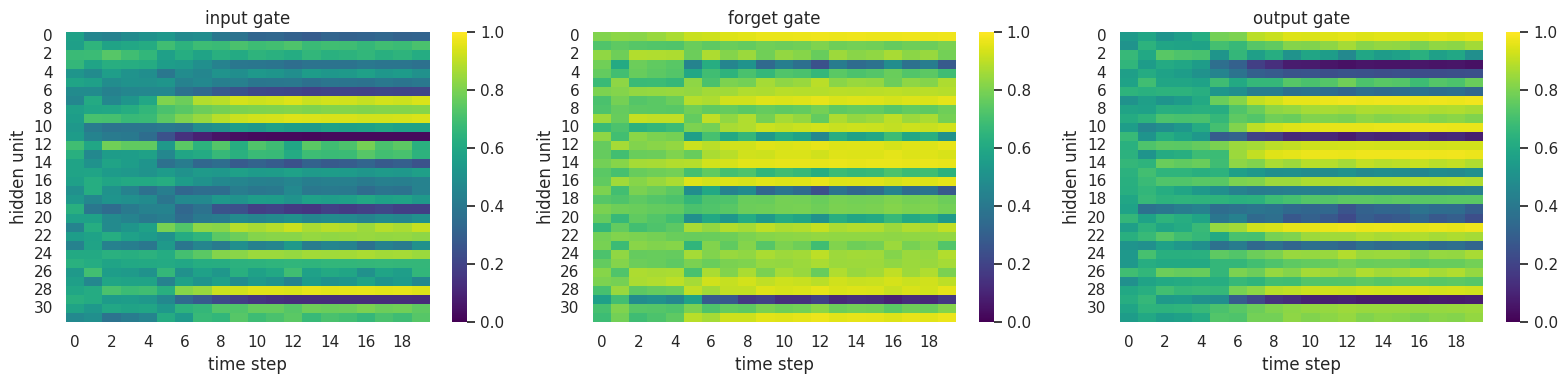

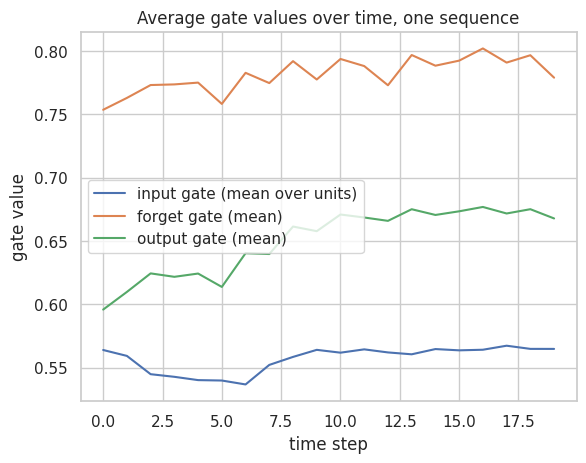

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, M, name in zip(ax, [I, F, O], ['input gate', 'forget gate', 'output gate']):
    sns.heatmap(M.T, ax=a, cmap='viridis', vmin=0, vmax=1, cbar=True); a.set(title=name, xlabel='time step', ylabel='hidden unit')
plt.tight_layout(); plt.show()
plt.plot(I.mean(1), label='input gate (mean over units)'); plt.plot(F.mean(1), label='forget gate (mean)'); plt.plot(O.mean(1), label='output gate (mean)')
plt.xlabel('time step'); plt.ylabel('gate value'); plt.legend(); plt.title('Average gate values over time, one sequence'); plt.show()